![Banner](../images/03_03_banner_spatial_analysis_multidimentional.png)


# Multidimensional Trend Analysis
 
This section introduces the analysis of trends in multidimensional raster datasets, focusing on how groundwater levels or storage evolve over time. Using multi-scale pixel-wise methods, we explore both long-term and seasonal changes captured within comprehensive spatiotemporal datasets, offering insight into the dynamics of groundwater systems.


## Overview

Three complementary approaches were employed to quantify long-term trends in
groundwater levels/storage using the bi-weekly raster time series (**2000-2020**).
All approaches applied pixel-wise ordinary least squares (OLS) linear regression
but differed in the temporal grouping of observations. This multi-scale framework
enabled assessment of the overall trend as well as intra-annual (monthly and
seasonal) variations in groundwater dynamics.


## Core concepts

The input dataset consists of bi-weekly GeoTIFF rasters named according to the
convention `watertable_YYYY_JJJ.tif` (equivalent to `gw_YYYY_JJJ.tif` in the
methods note), where `YYYY` denotes the year and `JJJ` is the Julian day of the
year (1-366). All raster files are parsed for date information using the Julian
day to generate accurate `datetime` objects and sorted chronologically. A
continuous time axis is created in **decimal years** as:

$$
t = \text{year} + \frac{\text{day of year} - 1}{\text{days in year}}
$$

accounting for leap years. This formulation ensures that regression slopes
represent the rate of change in groundwater units **per year**. All rasters are
stacked into a three-dimensional array of dimensions `(n_time, height, width)`.
NoData values are masked consistently using the native NoData flag of the input
rasters (or NaN where applicable).

### Pixel-wise linear regression

For each pixel and each temporal subset independently, a simple linear model is
fitted:

$$
y_i = \beta_0 + \beta_1 t_i + \epsilon_i
$$

where $y_i$ is the groundwater value at time $t_i$, $\beta_1$ is the slope
(trend magnitude), $\beta_0$ is the intercept, and $\epsilon_i$ is the random
error term. In this notebook the regression is performed by
`generate_trend_raster(..., trend_type="LINEAR")` (equivalent to
`scipy.stats.linregress` per pixel). Pixels with fewer than three valid
(non-NoData) observations in a given subset are masked as NaN in the output
rasters. The analysis returns three raster outputs per temporal subset:

- **Slope raster**: rate of groundwater change (units per year).
- **P-value raster**: two-tailed statistical significance of the slope.
- **R² raster**: coefficient of determination (goodness-of-fit).

All output GeoTIFFs inherit the original spatial properties (CRS, resolution,
extent, and transform) of the input rasters.

### Overall (full-period) trend analysis

The overall trend is computed using the complete set of bi-weekly observations
spanning 2000-2020. This provides a baseline assessment of the long-term linear
change across the entire study period without seasonal partitioning.

### Monthly trend analysis

To examine intra-annual variability, observations are grouped by calendar month
(January through December). For each month, bi-weekly rasters falling within that
month across all years (2000-2020) are retained (here as yearly monthly means),
and linear regression is applied independently to each monthly subset. This
results in 12 sets of output rasters (slope, p-value, and R² for each month),
revealing which months exhibit the strongest or most significant trends.

### Seasonal trend analysis

Three hydrologically relevant seasons are defined based on regional water-cycle
patterns:

- **Pre-monsoon**: 15 March to 15 July
- **Monsoon**: 16 July to 15 November
- **Winter**: 16 November to 14 March (of the following year)

Each bi-weekly raster is assigned to one season according to its acquisition date.
Winter spans the calendar-year boundary; the decimal-year time axis ensures
correct temporal spacing. Linear regression is performed separately on the
observations within each season, producing nine output rasters (three per season).
This captures trend behavior during distinct hydrological periods while
maintaining sufficient sample sizes for robust statistical inference.

### Implementation in this notebook

Analyses use Python 3 with `geolattice.spatial_analysis` (`MultidimensionalRaster`,
`generate_trend_raster`, `predict_using_trend_raster`, `raster_to_netcdf`),
plus `rasterio`, `xarray`, `numpy`, `pandas`, `matplotlib`, and `scipy`. An
optional **Mann-Kendall / Theil-Sen** overall trend is also demonstrated.


## Notebook roadmap

| Section | Temporal grouping | Slope unit | R_Code reference |
|---|---|---|---|
| **7. Overall** | All bi-weekly slices 2000-2020 | change **per year** | `01_yearly_trend` |
| **8. Monthly** | Yearly monthly means -> trend per calendar month | change **per year** (within that month) | `02_monthly_trend` |
| **9. Seasonal** | Premonsoon / Monsoon / Winter subsets | change **per year** | `03_seasonal_trend` |
| **10. Predict** | Extrapolate overall LINEAR fit | n/a | `predict_using_trend_raster` |

### Dependencies
- `geolattice.spatial_analysis` (`MultidimensionalRaster`, `generate_trend_raster`, `predict_using_trend_raster`, `raster_to_netcdf`)
- `rasterio`, `xarray`, `numpy`, `pandas`, `matplotlib`, `scipy`


## Setup

Locate the repository root, import the trend helpers, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

import os  # environment variables for GDAL/PROJ and process paths
import re  # regular expressions for filename / DOY parsing
import calendar  # month name helpers for seasonal labels
import ctypes  # preload libgdal into this process when needed
import warnings  # silence noisy third-party warnings in the tutorial
from pathlib import Path  # filesystem paths for locating sample data
from datetime import datetime, timedelta  # parse and construct timestamps

# Jupyter kernels do not load ~/.bashrc: preload user-local GDAL so osgeo works.
_GDAL_PREFIX = Path.home() / ".local" / "share" / "gdal-prefix"  # local GDAL install prefix
_GDAL_LIBDIR = _GDAL_PREFIX / "lib"  # directory containing libgdal
_GDAL_SO = _GDAL_LIBDIR / "libgdal.so.39"  # shared library file to preload
if _GDAL_SO.is_file():  # only adjust the environment when the local build exists
    os.environ["PATH"] = f"{_GDAL_PREFIX / 'bin'}{os.pathsep}{os.environ.get('PATH', '')}"  # prepend GDAL bin
    _ld = os.environ.get("LD_LIBRARY_PATH", "")  # existing LD_LIBRARY_PATH value
    os.environ["LD_LIBRARY_PATH"] = f"{_GDAL_LIBDIR}{os.pathsep}{_ld}" if _ld else str(_GDAL_LIBDIR)  # prepend lib dir
    _gdal_data = _GDAL_PREFIX / "share" / "gdal"  # GDAL_DATA support files
    _proj_data = _GDAL_PREFIX / "share" / "proj"  # PROJ datum / grid files
    if _gdal_data.is_dir():
        os.environ.setdefault("GDAL_DATA", str(_gdal_data))  # set GDAL_DATA if not already defined
    if _proj_data.is_dir():
        os.environ.setdefault("PROJ_DATA", str(_proj_data))  # PROJ 9+ data directory
        os.environ.setdefault("PROJ_LIB", str(_proj_data))  # legacy PROJ data directory
    ctypes.CDLL(str(_GDAL_SO), mode=ctypes.RTLD_GLOBAL)  # load libgdal into this process


import numpy as np  # array ops for rasters, masks, and numeric summaries
import pandas as pd  # tabular data frames and datetime indexes
import xarray as xr  # labeled multidimensional arrays (NetCDF / Zarr)
import matplotlib.pyplot as plt  # figure and axes creation for maps and charts
import rasterio  # GeoTIFF I/O and raster metadata

warnings.filterwarnings("ignore")  # keep the tutorial output readable

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

from geolattice.spatial_analysis import (  # import helpers from geolattice.spatial_analysis
    MultidimensionalRaster,  # cube wrapper around an xarray Dataset
    generate_trend_raster,  # per-pixel trend slope / significance
    predict_using_trend_raster,  # project a fitted trend to future times
    raster_to_netcdf,  # GeoTIFF series to NetCDF
)

WT_DIR = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh" / "watertable"  # path or tutorial parameter
OUT_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output" / "multidimensional_trend"  # path or tutorial parameter
OVERALL_DIR = OUT_DIR / "overall"  # path or tutorial parameter
MONTHLY_DIR = OUT_DIR / "monthly"  # path or tutorial parameter
SEASONAL_DIR = OUT_DIR / "seasonal"  # path or tutorial parameter
for d in (OUT_DIR, OVERALL_DIR, MONTHLY_DIR, SEASONAL_DIR):  # iterate over items
    d.mkdir(parents=True, exist_ok=True)  # create the output folder if needed

# Match R_Code trend period (full archive also has 1985-1999)
YEAR_START, YEAR_END = 2000, 2020  # YEAR_START

print(f"Repo:     {ROOT}")  # confirm paths / environment
print(f"WT dir:   {WT_DIR} exists={WT_DIR.is_dir()}")  # confirm paths / environment
print(f"Years:    {YEAR_START}-{YEAR_END}")  # confirm paths / environment
print(f"Output:   {OUT_DIR}")  # confirm paths / environment


Repo:     /home/zia207/Github/GeoLattice
WT dir:   /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/watertable exists=True
Years:    2000-2020
Output:   /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_trend


## Helpers

Parse `watertable_YYYY_DOY.tif`, stack into a `MultidimensionalRaster`, assign Bangladesh
seasons, and convert timestamps to **decimal years** so LINEAR slopes are in
**units per year** (as in `R_Code/00_methods_trend_analysis.ipynb`).


In [2]:
# The following helper functions are used to process and analyze water table raster time series
# as part of a multidimensional trend analysis. These helpers handle file name parsing, time
# conversion, seasonal assignment, raster stacking, exporting geotiffs, and plotting results.

def parse_doy_filename(path: Path, prefix: str = "watertable") -> datetime:
    """
    Parse filenames like '{prefix}_YYYY_DOY.tif' into Python datetime objects.

    - Extracts the year and day-of-year (DOY) from the file name.
    - Converts to a datetime representing that day in the specified year.

    Used to get the observation date for each raster file.

    Example:
        watertable_2017_174.tif  =>  datetime(2017, 6, 23)
    """

    m = re.match(rf"{re.escape(prefix)}_(\d{{4}})_(\d{{1,3}})$", path.stem, re.IGNORECASE)  # m
    if not m:
        raise ValueError(f"Unexpected filename: {path.name}")  # fail with a clear error message
    year, doy = int(m.group(1)), int(m.group(2))  # year
    if not 1 <= doy <= 366:
        raise ValueError(f"Invalid DOY {doy} in {path.name}")  # fail with a clear error message
    return datetime(year, 1, 1) + timedelta(days=doy - 1)  # return the computed result

def decimal_year(dt: datetime) -> float:
    """
    Convert a datetime object to a decimal year (e.g., 2017.5 for mid-2017).

    - Accounts for leap years.
    - The fraction is days elapsed divided by total days in the year.

    Useful for fitting linear trends in 'units per year' with irregular time steps.
    """

    year_start = datetime(dt.year, 1, 1)  # year_start
    day_of_year = (dt - year_start).days  # day_of_year
    days_in_year = 366 if (dt.year % 4 == 0 and (dt.year % 100 != 0 or dt.year % 400 == 0)) else 365  # days_in_year
    return dt.year + day_of_year / days_in_year  # return the computed result

def get_bangladesh_season(dt: datetime):
    """
    Assign a Bangladesh hydrological season to a given date.

    Seasons are:
      - 'Premonsoon': roughly mid-March to mid-July
      - 'Monsoon': roughly mid-July to mid-November
      - 'Winter': roughly mid-November to mid-March

    Returns one of the above season names or None if the date does not fit.
    Used for summarizing seasonal trends.

    """
    m, d = dt.month, dt.day  # m
    if (m == 3 and d >= 15) or (4 <= m <= 6) or (m == 7 and d <= 15):
        return "Premonsoon"  # return the computed result
    if (m == 7 and d >= 16) or (8 <= m <= 10) or (m == 11 and d <= 15):
        return "Monsoon"  # return the computed result
    if (m == 11 and d >= 16) or (m == 12) or (1 <= m <= 2) or (m == 3 and d <= 14):
        return "Winter"  # return the computed result
    return None  # return the computed result

def stack_geotiffs_to_mdr(paths, times, variable_name: str = "watertable") -> MultidimensionalRaster:
    """
    Read a series of GeoTIFF raster files (one per time step) and stack into an
    xarray-based MultidimensionalRaster.

    - Reads each raster as a 2D array, replacing nodata values with np.nan.
    - Calculates spatial coordinates using the GeoTIFF's affine transform.
    - Stacks the arrays on a new 'time' dimension with user-supplied coordinates.

    Returns a MultidimensionalRaster ready for analysis.
    """

    arrays = []  # arrays
    xs = ys = None  # xs
    for path in paths:  # iterate over items
        with rasterio.open(path) as src:  # open a context-managed resource
            data = src.read(1).astype("float32")  # cast to the target dtype
            nodata = src.nodata  # nodata
            if nodata is not None:
                data = np.where(data == nodata, np.nan, data)  # compute data
            data = np.where(np.abs(data) > 1e30, np.nan, data)  # compute data
            transform = src.transform  # transform
            height, width = data.shape  # height
            xs = transform.c + (np.arange(width) + 0.5) * transform.a  # compute xs
            ys = transform.f + (np.arange(height) + 0.5) * transform.e  # compute ys
            arrays.append(data)

    da = xr.DataArray(  # da
        np.stack(arrays, axis=0),  # set np.stack(arrays
        dims=("time", "y", "x"),  # dims
        coords={  # coords
            "time": np.asarray(times, dtype="datetime64[ns]"),  # set "time": np.asarray(times
            "y": ys,
            "x": xs,
        },
        name=variable_name,  # name
    )
    return MultidimensionalRaster(da)  # return the computed result

def with_decimal_year_time(mdr: MultidimensionalRaster, variable: str = "watertable") -> MultidimensionalRaster:
    """
    Replace the datetime-based 'time' coordinate in a MultidimensionalRaster with a
    decimal year float coordinate for trend fitting.

    - Retains the original datetime coordinate as 'date'.
    - Updates attributes to describe the new coordinate.

    Allows regression/trend analysis in year-based units.
    """

    da = mdr.dataset[variable]  # da
    dates = pd.to_datetime(da.time.values)  # parse timestamps
    t_dec = np.array([decimal_year(d.to_pydatetime()) for d in dates], dtype=np.float64)  # compute t_dec
    da2 = da.assign_coords(date=("time", dates), time=("time", t_dec))  # da2
    da2.time.attrs.update(units="decimal_year", long_name="Decimal year")  # set da2.time.attrs.update(units
    return MultidimensionalRaster(da2)  # return the computed result

def write_geotiff_from_array(array: np.ndarray, out_path: Path, profile_src: Path, nodata=np.nan):
    """
    Write a single-band array to a GeoTIFF file, copying metadata (CRS, affine, etc.)
    from a reference GeoTIFF.

    - Converts the array to float32.
    - Sets compression (LZW) and nodata value.
    - Ensures parent directory exists.

    Used to save processed or derived raster outputs for mapping or further analysis.
    """
    with rasterio.open(profile_src) as src:  # open a context-managed resource
        profile = src.profile.copy()  # profile
    profile.update(dtype="float32", count=1, nodata=nodata, compress="LZW")  # set profile.update(dtype
    out_path.parent.mkdir(parents=True, exist_ok=True)  # set out_path.parent.mkdir(parents
    with rasterio.open(out_path, "w", **profile) as dst:  # open a context-managed resource
        dst.write(np.asarray(array, dtype=np.float32), 1)  # compute dst.write(np.asarray(array

def export_trend_bands(trend: MultidimensionalRaster, out_dir: Path, stem: str, profile_src: Path):
    """
    Save multiple trend result layers (slope, p-value, R²) as GeoTIFF files using
    write_geotiff_from_array.

    - Exports each trend output (if present) with a standardized filename.
    - Returns list of written filenames for reference/logging.
    """
    ds = trend.dataset  # ds
    mapping = {  # mapping
        "slope": f"{stem}_slope.tif",
        "p_value": f"{stem}_pvalue.tif",
        "r2": f"{stem}_R2.tif",
    }
    written = []  # written
    for var, fname in mapping.items():  # iterate over items
        if var not in ds:
            continue  # skip this candidate
        path = out_dir / fname  # path
        write_geotiff_from_array(ds[var].values, path, profile_src)
        written.append(path.name)
    return written  # return the computed result

def plot_trend_triplet(trend: MultidimensionalRaster, title: str, cmap_slope="RdBu_r"):
    """
    Display quicklook maps of the spatial patterns in trend results:
    - Slope (rate of change, units/year)
    - p-value (statistical significance)
    - R² (coefficient of determination)

    Uses matplotlib with side-by-side subplots for compact visualization.
    Color scales are automatically set for robust and interpretable display.
    """
    ds = trend.dataset  # ds
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))  # create the figure and axes
    slope = ds["slope"]  # slope
    vmax = np.nanpercentile(np.abs(slope.values), 98)  # compute vmax
    vmax = max(float(vmax), 1e-6)  # vmax
    im0 = axes[0].imshow(slope.values, cmap=cmap_slope, vmin=-vmax, vmax=vmax, origin="upper")  # show a 2-D array as an image
    axes[0].set_title("Slope (units/year)")  # panel title
    fig.colorbar(im0, ax=axes[0], fraction=0.046)  # add a colorbar

    im1 = axes[1].imshow(ds["p_value"].values, cmap="viridis_r", vmin=0, vmax=0.1, origin="upper")  # show a 2-D array as an image
    axes[1].set_title("p-value")  # panel title
    fig.colorbar(im1, ax=axes[1], fraction=0.046)  # add a colorbar

    im2 = axes[2].imshow(ds["r2"].values, cmap="magma", vmin=0, vmax=1, origin="upper")  # show a 2-D array as an image
    axes[2].set_title("R2")  # panel title
    fig.colorbar(im2, ax=axes[2], fraction=0.046)  # add a colorbar

    for ax in axes:  # iterate over items
        ax.set_xticks([])  # configure tick labels
        ax.set_yticks([])  # configure tick labels
    fig.suptitle(title, y=1.02)  # set fig.suptitle(title
    plt.tight_layout()  # reduce unused whitespace
    plt.show()  # render the figure

print("Helpers ready.")  # status / summary print


Helpers ready.


## Load watertable cube (2000-2020)

Bi-weekly `watertable_YYYY_DOY.tif` files are stacked with datetime coordinates, then
re-expressed on a **decimal-year** time axis for trend fitting.


In [3]:
paths = sorted(  # paths
    [
        p
        for p in WT_DIR.glob("watertable_*.tif")
        if YEAR_START <= int(p.stem.split("_")[1]) <= YEAR_END
    ],
    key=lambda p: parse_doy_filename(p),  # key
)
if len(paths) < 3:
    raise FileNotFoundError(f"Need >=3 watertable rasters in {YEAR_START}-{YEAR_END} under {WT_DIR}")  # fail with a clear error message

times = [parse_doy_filename(p) for p in paths]  # times
REF_TIF = paths[0]  # REF_TIF

print(f"Loading {len(paths)} rasters ({times[0].date()} -> {times[-1].date()})...")  # status / summary print
wt_mdr = stack_geotiffs_to_mdr(paths, times, variable_name="watertable")  # build multidimensional layer
wt_dec = with_decimal_year_time(wt_mdr, "watertable")  # wt_dec

print(wt_mdr)  # status / summary print
print(wt_dec)  # status / summary print
print(f"Decimal year range: {float(wt_dec.dataset.time.min()):.3f} -> {float(wt_dec.dataset.time.max()):.3f}")  # status / summary print
print(f"Reference GeoTIFF: {REF_TIF.name}")  # status / summary print


Loading 483 rasters (2000-01-01 -> 2020-12-18)...


MultidimensionalRaster(variables=[watertable], dims={time: 483, y: 669, x: 479})
MultidimensionalRaster(variables=[watertable], dims={y: 669, x: 479, time: 483})
Decimal year range: 2000.000 -> 2020.962
Reference GeoTIFF: watertable_2000_001.tif


## Overall (full-period) trend

LINEAR OLS on every bi-weekly observation from 2000-2020
(`generate_trend_raster(..., trend_type="LINEAR")`).

Outputs: intercept, slope (per year), R², p-value: same products as
`R_Code/01_yearly_trend.ipynb`.


Computing overall LINEAR trend...


MultidimensionalRaster(variables=[intercept, slope, r2, p_value], dims={y: 669, x: 479})


Wrote: watertable_overall_slope.tif, watertable_overall_pvalue.tif, watertable_overall_R2.tif
NetCDF: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_trend/watertable_overall_trend.nc


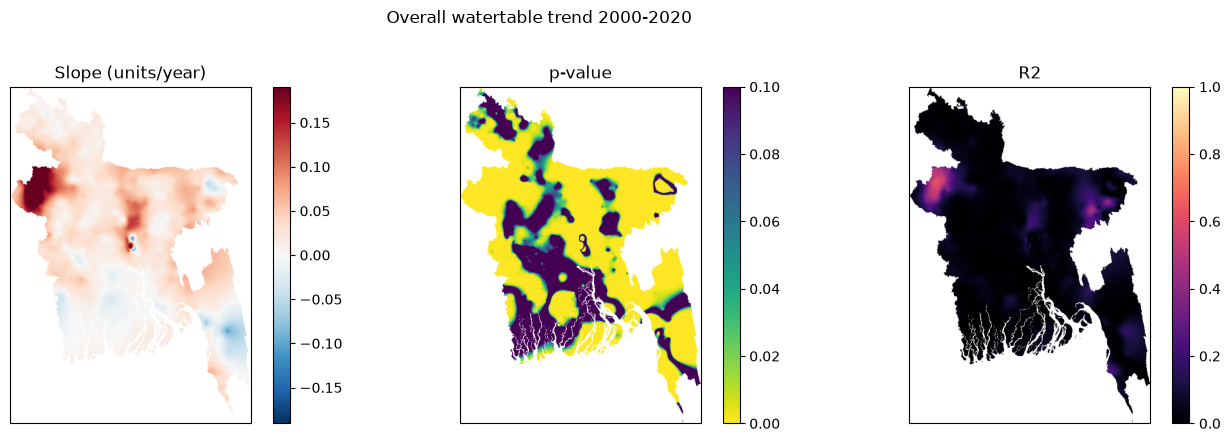

Slope (units/yr)  mean=0.0297  median=0.0198  % declining=16.8


In [4]:
print("Computing overall LINEAR trend...")  # status / summary print
trend_overall = generate_trend_raster(  # trend_overall
    wt_dec,
    variable="watertable",  # variable
    dimension="time",  # dimension
    trend_type="LINEAR",  # trend_type
)
print(trend_overall)  # status / summary print

written = export_trend_bands(trend_overall, OVERALL_DIR, "watertable_overall", REF_TIF)  # written
nc_overall = OUT_DIR / "watertable_overall_trend.nc"  # build a filesystem path
raster_to_netcdf(trend_overall, nc_overall, overwrite=True)  # set raster_to_netcdf(trend_overall
print("Wrote:", ", ".join(written))  # status / summary print
print("NetCDF:", nc_overall)  # status / summary print

plot_trend_triplet(trend_overall, f"Overall watertable trend {YEAR_START}-{YEAR_END}")

slope = trend_overall.dataset["slope"].values  # slope
valid = np.isfinite(slope)  # compute valid
print(  # status / summary print
    f"Slope (units/yr)  mean={np.nanmean(slope):.4f}  "  # aggregate along time or groups
    f"median={np.nanmedian(slope):.4f}  "  # compute f"median
    f"% declining={(np.nanmean(slope[valid] < 0) * 100):.1f}"  # aggregate along time or groups
)


### Optional: Mann-Kendall / Theil-Sen

The Mann-Kendall test and Theil-Sen estimator provide non-parametric methods for detecting monotonic trends in time series data.

**Mann-Kendall trend test**:

- For a time series $x_1, x_2, \ldots, x_n$, compute the **Mann-Kendall statistic** $S$:

$$
S = \sum_{i=1}^{n-1} \sum_{j=i+1}^{n} \mathrm{sgn}(x_j - x_i)
$$

where the sign function $\mathrm{sgn}(x)$ is defined as:

$$
\mathrm{sgn}(x) = \begin{cases}
  +1 & \text{if } x > 0 \\
  0  & \text{if } x = 0 \\
  -1 & \text{if } x < 0
\end{cases}
$$

- The normalized value of $S$ gives **Kendall's tau** ($\tau$), a correlation between time and the variable.
- A p-value is computed to test the null hypothesis of no trend.

**Theil-Sen slope estimator**:

- For all $i < j$, compute all pairwise slopes:

    $$
    m_{ij} = \frac{x_j - x_i}{t_j - t_i}
    $$

    where $t_i$ and $t_j$ are the time points.

- The **Theil-Sen slope** is the median of all $m_{ij}$.
- The **intercept** is estimated as the median of $[x_i - (\text{slope} \times t_i) ]$.

This method is more robust to outliers than ordinary least squares (OLS) regression.

Setting `trend_type="MANN_KENDALL"` returns the following statistics: Kendall's tau (τ), p-value, Theil-Sen slope (per year), and intercept.


Computing overall MANN_KENDALL trend...


MultidimensionalRaster(variables=[tau, p_value, slope, intercept], dims={y: 669, x: 479})
Wrote: watertable_overall_MK_slope.tif watertable_overall_MK_pvalue.tif


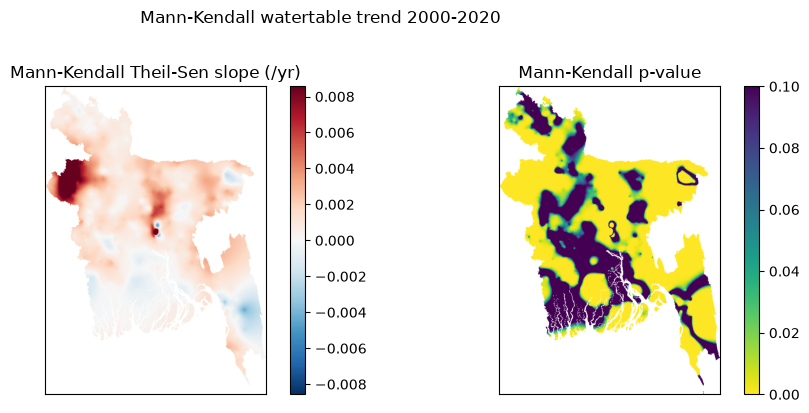

In [5]:
print("Computing overall MANN_KENDALL trend...")  # status / summary print
trend_mk = generate_trend_raster(  # trend_mk
    wt_dec,
    variable="watertable",  # variable
    dimension="time",  # dimension
    trend_type="MANN_KENDALL",  # trend_type
)
print(trend_mk)  # status / summary print

mk_slope_path = OVERALL_DIR / "watertable_overall_MK_slope.tif"  # build a filesystem path
mk_p_path = OVERALL_DIR / "watertable_overall_MK_pvalue.tif"  # build a filesystem path
write_geotiff_from_array(trend_mk.dataset["slope"].values, mk_slope_path, REF_TIF)
write_geotiff_from_array(trend_mk.dataset["p_value"].values, mk_p_path, REF_TIF)
print("Wrote:", mk_slope_path.name, mk_p_path.name)  # status / summary print

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # create the figure and axes
s = trend_mk.dataset["slope"]  # s
vmax = max(float(np.nanpercentile(np.abs(s.values), 98)), 1e-6)  # compute vmax
im0 = axes[0].imshow(s.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="upper")  # show a 2-D array as an image
axes[0].set_title("Mann-Kendall Theil-Sen slope (/yr)")  # panel title
fig.colorbar(im0, ax=axes[0], fraction=0.046)  # add a colorbar
im1 = axes[1].imshow(trend_mk.dataset["p_value"].values, cmap="viridis_r", vmin=0, vmax=0.1, origin="upper")  # show a 2-D array as an image
axes[1].set_title("Mann-Kendall p-value")  # panel title
fig.colorbar(im1, ax=axes[1], fraction=0.046)  # add a colorbar
for ax in axes:  # iterate over items
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels
fig.suptitle(f"Mann-Kendall watertable trend {YEAR_START}-{YEAR_END}", y=1.02)
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure


## Monthly trend analysis

1. Average bi-weekly slices into **year-month** means.  
2. For each calendar month (Jan-Dec), fit a LINEAR trend across years.

Slope = groundwater change **per year** for that calendar month
(`R_Code/02_monthly_trend.ipynb`).


In [6]:
# Work from datetime-indexed cube for groupby
da = wt_mdr.dataset["watertable"]  # da

print("Computing year-month means...")  # status / summary print
monthly_avg = da.groupby("time.year").map(  # monthly_avg
    lambda x: x.groupby("time.month").mean("time", skipna=True)
)
print(monthly_avg)  # status / summary print

monthly_trends = {}  # monthly_trends
for month in range(1, 13):  # iterate over items
    month_name = calendar.month_name[month]  # month_name
    try:  # attempt optional or version-sensitive call
        month_da = monthly_avg.sel(month=month)  # select along coordinates or indices
    except Exception:  # handle the failure path
        print(f"  skip {month_name}: month not in dataset")  # status / summary print
        continue  # skip this candidate

    if "year" in month_da.dims:
        month_da = month_da.dropna("year", how="all")  # month_da
        years = month_da["year"].values.astype(np.float64)  # cast to the target dtype
        if len(years) < 3:
            print(f"  skip {month_name}: only {len(years)} years")  # status / summary print
            continue  # skip this candidate
        month_da = month_da.assign_coords(time=("year", years)).swap_dims({"year": "time"})  # month_da
    else:
        print(f"  skip {month_name}: unexpected dims {month_da.dims}")  # status / summary print
        continue  # skip this candidate

    drop_coords = [c for c in ("month", "year") if c in month_da.coords]  # drop_coords
    if drop_coords:
        month_da = month_da.drop_vars(drop_coords)  # month_da
    month_da.name = "watertable"  # set month_da.name
    mdr_m = MultidimensionalRaster(month_da)  # mdr_m

    print(f"-> {month_name}: {len(years)} yearly means ({int(years.min())}-{int(years.max())})")  # status / summary print
    tr = generate_trend_raster(  # tr
        mdr_m, variable="watertable", dimension="time", trend_type="LINEAR"  # mdr_m
    )
    monthly_trends[month] = tr  # set monthly_trends[month]
    stem = f"watertable_{month_name}"  # stem
    written = export_trend_bands(tr, MONTHLY_DIR, stem, REF_TIF)  # written
    print(f"   wrote {', '.join(written)}")  # status / summary print

print(f"\nMonthly trend sets: {len(monthly_trends)} / 12")  # status / summary print


Computing year-month means...


<xarray.DataArray 'watertable' (year: 21, y: 669, x: 479, month: 12)> Size: 323MB
array([[[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan]],

        [[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan]],

        [[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
...
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan]],

        [[nan, nan, nan, ..., nan, nan

   wrote watertable_January_slope.tif, watertable_January_pvalue.tif, watertable_January_R2.tif
-> February: 21 yearly means (2000-2020)


   wrote watertable_February_slope.tif, watertable_February_pvalue.tif, watertable_February_R2.tif
-> March: 21 yearly means (2000-2020)


   wrote watertable_March_slope.tif, watertable_March_pvalue.tif, watertable_March_R2.tif
-> April: 21 yearly means (2000-2020)


   wrote watertable_April_slope.tif, watertable_April_pvalue.tif, watertable_April_R2.tif
-> May: 21 yearly means (2000-2020)


... (4 outputs left out)

   wrote watertable_September_slope.tif, watertable_September_pvalue.tif, watertable_September_R2.tif
-> October: 21 yearly means (2000-2020)


   wrote watertable_October_slope.tif, watertable_October_pvalue.tif, watertable_October_R2.tif
-> November: 21 yearly means (2000-2020)


   wrote watertable_November_slope.tif, watertable_November_pvalue.tif, watertable_November_R2.tif
-> December: 21 yearly means (2000-2020)


   wrote watertable_December_slope.tif, watertable_December_pvalue.tif, watertable_December_R2.tif

Monthly trend sets: 12 / 12


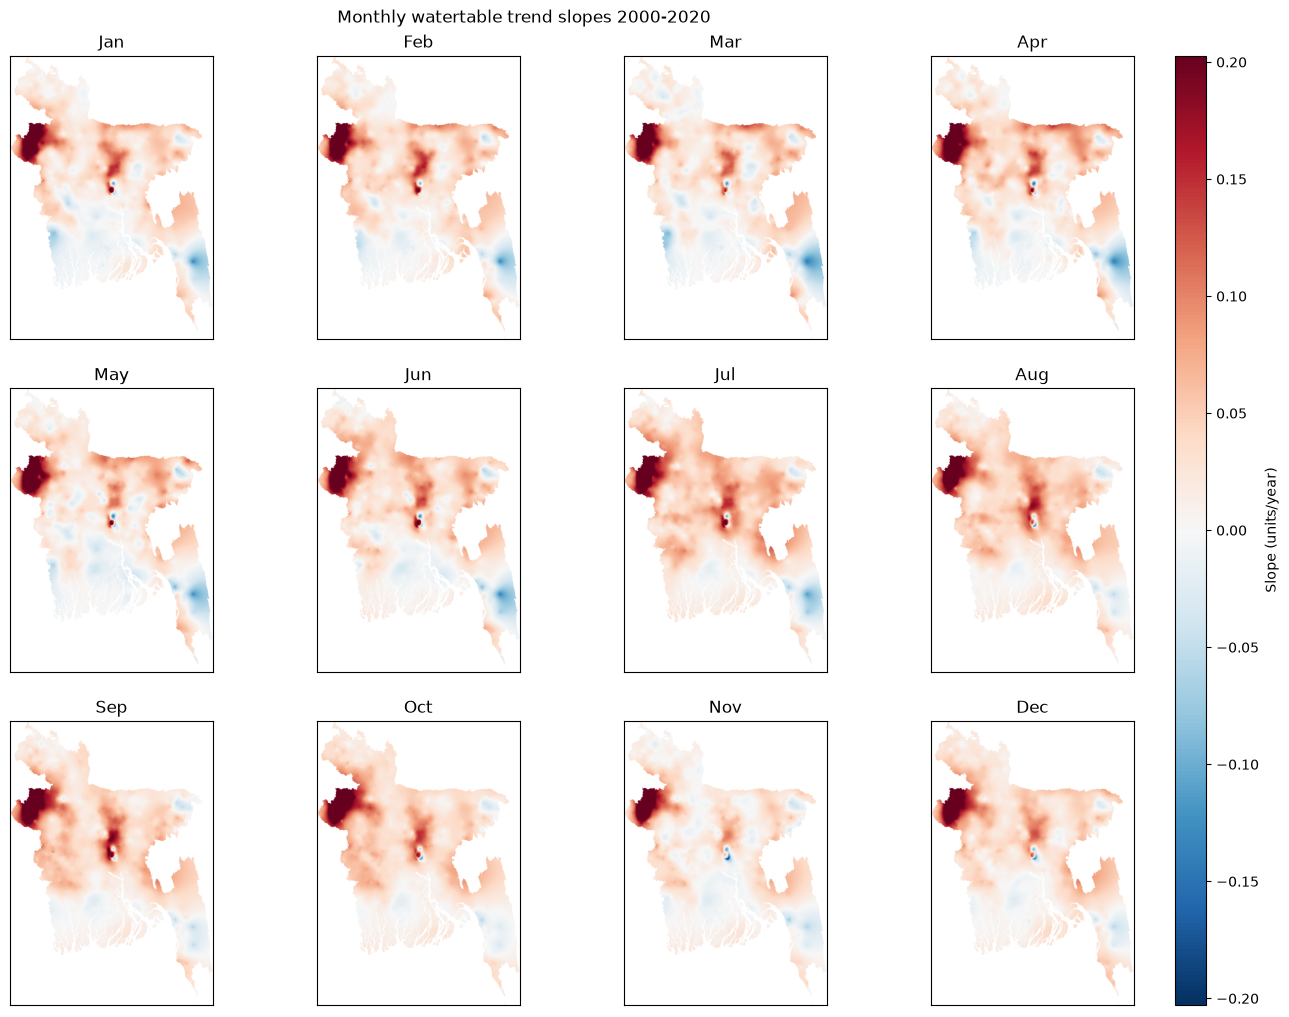

In [7]:
# 12-panel slope map
fig, axes = plt.subplots(3, 4, figsize=(14, 10))  # create the figure and axes
slopes = [monthly_trends[m].dataset["slope"].values for m in sorted(monthly_trends)]  # slopes
vmax = max(float(np.nanpercentile(np.abs(np.stack(slopes)), 98)), 1e-6)  # compute vmax
im = None  # im

for ax, month in zip(axes.ravel(), range(1, 13)):  # iterate over items
    name = calendar.month_abbr[month]  # name
    if month not in monthly_trends:
        ax.set_visible(False)  # style the axes
        continue  # skip this candidate
    im = ax.imshow(  # im
        monthly_trends[month].dataset["slope"].values,
        cmap="RdBu_r",  # cmap
        vmin=-vmax,  # vmin
        vmax=vmax,  # vmax
        origin="upper",  # origin
    )
    ax.set_title(name)  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

# Reduce between column space: set w_pad lower
plt.tight_layout(w_pad=0.2, h_pad=2.0)  # significantly reduce space between columns

# Move colorbar to the right of all panels and adjust its size/position
cbar = fig.colorbar(  # cbar
    im, 
    ax=axes,  # ax
    orientation="vertical",  # orientation
    fraction=0.025,  # fraction
    pad=0.03,  # pad
    aspect=30,  # aspect
    label="Slope (units/year)"  # label
)

fig.suptitle(f"Monthly watertable trend slopes {YEAR_START}-{YEAR_END}", y=1.01)
plt.show()  # render the figure


## Seasonal trend analysis

Assign each bi-weekly slice to Premonsoon / Monsoon / Winter and run LINEAR trend
separately on each seasonal subset (`R_Code/03_seasonal_trend.ipynb`).
Decimal-year time keeps Winter's cross-year samples correctly spaced.


In [8]:
da_dec = wt_dec.dataset["watertable"]  # da_dec
dates = pd.to_datetime(da_dec["date"].values)  # parse timestamps
seasons = np.array([get_bangladesh_season(d.to_pydatetime()) for d in dates])  # compute seasons

seasonal_trends = {}  # seasonal_trends
for season in ("Premonsoon", "Monsoon", "Winter"):  # iterate over items
    mask = seasons == season  # mask
    n = int(mask.sum())  # n
    if n < 3:
        print(f"WARNING {season}: only {n} slices -> skip")  # status / summary print
        continue  # skip this candidate

    sub = da_dec.isel(time=mask)  # select along coordinates or indices
    if "date" in sub.coords:
        sub = sub.drop_vars("date")  # sub
    sub.name = "watertable"  # set sub.name
    mdr_s = MultidimensionalRaster(sub)  # mdr_s

    t_min, t_max = float(sub.time.min()), float(sub.time.max())  # t_min
    print(f"-> {season}: {n} slices  decimal years {t_min:.2f}-{t_max:.2f}")  # status / summary print
    tr = generate_trend_raster(  # tr
        mdr_s, variable="watertable", dimension="time", trend_type="LINEAR"  # mdr_s
    )
    seasonal_trends[season] = tr  # set seasonal_trends[season]
    written = export_trend_bands(tr, SEASONAL_DIR, f"watertable_{season}", REF_TIF)  # written
    print(f"   wrote {', '.join(written)}")  # status / summary print

slope_stack = xr.concat(  # slope_stack
    [
        seasonal_trends[s].dataset["slope"].expand_dims(season=[s])
        for s in seasonal_trends
    ],
    dim="season",  # dim
)
slope_stack.name = "slope"  # set slope_stack.name
slope_ds = slope_stack.to_dataset()  # slope_ds
nc_season = OUT_DIR / "watertable_seasonal_trend_slope.nc"  # build a filesystem path
slope_ds.to_netcdf(nc_season)
print("Seasonal slope NetCDF:", nc_season)  # status / summary print


-> Premonsoon: 168 slices  decimal years 2000.22-2020.52


   wrote watertable_Premonsoon_slope.tif, watertable_Premonsoon_pvalue.tif, watertable_Premonsoon_R2.tif
-> Monsoon: 147 slices  decimal years 2000.57-2020.83


   wrote watertable_Monsoon_slope.tif, watertable_Monsoon_pvalue.tif, watertable_Monsoon_R2.tif
-> Winter: 168 slices  decimal years 2000.00-2020.96


   wrote watertable_Winter_slope.tif, watertable_Winter_pvalue.tif, watertable_Winter_R2.tif
Seasonal slope NetCDF: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_trend/watertable_seasonal_trend_slope.nc


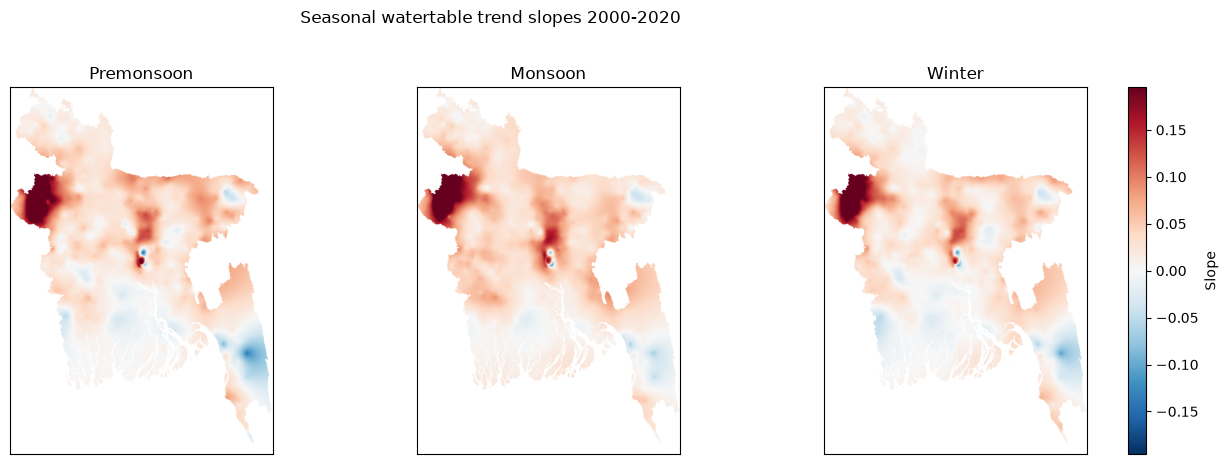

Premonsoon    mean slope=+0.0307  % declining=19.5  median R2=0.024
Monsoon       mean slope=+0.0400  % declining=9.5  median R2=0.066
Winter        mean slope=+0.0268  % declining=21.8  median R2=0.032


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))  # create the figure and axes
slopes = [seasonal_trends[s].dataset["slope"].values for s in seasonal_trends]  # slopes
vmax = max(float(np.nanpercentile(np.abs(np.stack(slopes)), 98)), 1e-6)  # compute vmax
im = None  # im

for ax, season in zip(axes, seasonal_trends):  # iterate over items
    im = ax.imshow(  # im
        seasonal_trends[season].dataset["slope"].values,
        cmap="RdBu_r",  # cmap
        vmin=-vmax,  # vmin
        vmax=vmax,  # vmax
        origin="upper",  # origin
    )
    ax.set_title(season)  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

fig.suptitle(f"Seasonal watertable trend slopes {YEAR_START}-{YEAR_END}", y=1.02)
plt.tight_layout(w_pad=0.5)  # Reduce space between columns

# Show colorbar beside axes
cbar = fig.colorbar(  # cbar
    im, ax=axes,  # im
    orientation='vertical',  # orientation
    fraction=0.035,  # fraction
    pad=0.03,  # pad
    label="Slope"  # label
)

plt.show()  # render the figure

for season, tr in seasonal_trends.items():  # iterate over items
    s = tr.dataset["slope"].values  # s
    v = np.isfinite(s)  # compute v
    print(  # status / summary print
        f"{season:12}  mean slope={np.nanmean(s):+.4f}  "  # aggregate along time or groups
        f"% declining={100 * np.nanmean(s[v] < 0):.1f}  "  # aggregate along time or groups
        f"median R2={np.nanmedian(tr.dataset['r2'].values):.3f}"  # compute f"median R2
    )


## Predict using trend raster (demo)

Project overall LINEAR trend forward to 2025 and 2030 with
`predict_using_trend_raster` (ArcGIS *Predict Using Trend Raster*).


MultidimensionalRaster(variables=[watertable], dims={y: 669, x: 479, time: 2})


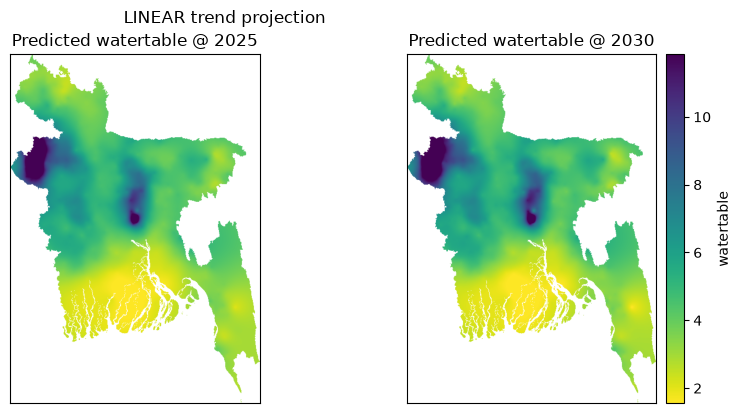

Wrote /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_trend/watertable_overall_predict_2025_2030.nc


In [10]:
future_years = [2025.0, 2030.0]  # future_years
pred = predict_using_trend_raster(  # pred
    trend_overall,
    dimension_values=future_years,  # dimension_values
    dimension_name="time",  # dimension_name
)
print(pred)  # status / summary print

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # create the figure and axes
var = pred.variables[0]  # var
da_pred = pred.dataset[var]  # da_pred
vmin = float(np.nanpercentile(da_pred.values, 2))  # compute vmin
vmax = float(np.nanpercentile(da_pred.values, 98))  # compute vmax
for ax, t in zip(axes, future_years):  # iterate over items
    im = ax.imshow(da_pred.sel(time=t).values, cmap="viridis_r", vmin=vmin, vmax=vmax, origin="upper")  # select along coordinates or indices
    ax.set_title(f"Predicted watertable @ {t:.0f}")  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels

# Reduce space between two columns (w_pad=0.1), and move colorbar closer to axes
plt.tight_layout(w_pad=0.1)  # reduce unused whitespace

# Move the colorbar to the right, closer to the axes
cbar = fig.colorbar(  # cbar
    im, 
    ax=axes.tolist(),  # ax
    fraction=0.045,     # slightly bigger colorbar
    pad=0.01,           # reduce padding
    label="watertable",  # label
    location="right"  # location
)
fig.suptitle("LINEAR trend projection", y=1.02)
plt.show()  # render the figure

pred_nc = OUT_DIR / "watertable_overall_predict_2025_2030.nc"  # build a filesystem path
raster_to_netcdf(pred, pred_nc, overwrite=True)  # set raster_to_netcdf(pred
print("Wrote", pred_nc)  # status / summary print


## Summary

| Product | Path |
|---|---|
| Overall LINEAR slope / p / R² | `Data/03_spatial_analysis/NetCDF/output/multidimensional_trend/overall/` |
| Overall LINEAR NetCDF | `.../watertable_overall_trend.nc` |
| Overall Mann-Kendall slope / p | `.../overall/watertable_overall_MK_*.tif` |
| Monthly LINEAR (12 x 3) | `.../monthly/` |
| Seasonal LINEAR (3 x 3) | `.../seasonal/` |
| Seasonal slope NetCDF | `.../watertable_seasonal_trend_slope.nc` |
| LINEAR predictions 2025/2030 | `.../watertable_overall_predict_2025_2030.nc` |

### Key takeaways

1. Use a **decimal-year** time axis so `generate_trend_raster` slopes are **per year**.
2. Overall, monthly, and seasonal groupings answer different questions about when change occurs.
3. Prefer **Mann-Kendall / Theil-Sen** when outliers or non-Gaussian residuals matter.
4. `predict_using_trend_raster` extrapolates fitted coefficients to new times: interpret cautiously outside the calibration period.
